# Lab 2 — Swing com o UFactory Lite 6

Notebook com **tudo** o que foi feito no Lab 2: a teoria, o código a correr e os
resultados. Complementa o [GUIA.md](GUIA.md) (mais detalhe em texto) e usa os
módulos de `src/` — o notebook não duplica código, importa-o, por isso qualquer
correção em `src/` aparece aqui ao correr de novo.

Enunciado: [lab_2_2026.pdf](lab_2_2026.pdf) · Prazo: **13/11/2026, 23:59:59**

| Secção | Conteúdo |
|---|---|
| 0 | Setup |
| 1 | Configuração e limites do fabricante |
| 2 | **Tarefa 1** — cinemática direta (DH modificado) |
| 3 | IK numérica (só para verificação offline) |
| 4 | **Tarefa 2** — trajetória de swing e viabilidade |
| 5 | A singularidade do pulso |
| 6 | Explorar parâmetros |
| 7 | **Tarefa 3** — executar no robô |
| 8 | **Tarefa 4** — precisão da IK do robô |
| 9 | Checklist do laboratório e limitações |

> As células que falam com o robô estão protegidas por `RUN_ON_ROBOT = False`.
> Tudo o resto corre offline. Algumas células demoram ~20–40 s (IK numérica
> em ~600 pontos).

## 0. Setup

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("src"))   # o notebook está em Lab2/
%load_ext autoreload
%autoreload 2

import config as C
from kinematics import tool_transform, T_from_pose
from kinematics import DH, fk, fk_pose, link_transform, rpy_from_R, R_from_rpy, rotvec, orientation_error_deg, ik_numeric
from trajectory import command_poses
from trajectory import DEFAULTS, quintic, swing_angles, swing_trajectory, joint_trajectory, check_feasibility, plot as plot_traj
from robot import wrap180, pose_sdk

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 100

## 1. Configuração e limites do fabricante (`src/config.py`)

Todos os números da datasheet estão num só sítio. Os **limites e velocidades
estão marcados CONFIRMAR** — foram escritos de memória e devem ser verificados
na datasheet do Lite 6 (a tabela DH, essa, já está confirmada: secção 2). Convenções: mm, graus, roll/pitch/yaw com $R = R_z(\text{yaw})\,R_y(\text{pitch})\,R_x(\text{roll})$
— as mesmas do SDK com `is_radian=False`.

As verificações da Tarefa 2 só aceitam trajetórias que usem no máximo
`SAFETY_FACTOR` = 80 % dos limites.

In [2]:
print(f"IP do robô          : {C.ROBOT_IP}  (ou variável de ambiente LITE6_IP)")
for i, (lo, hi) in enumerate(C.JOINT_LIMITS, 1):
    print(f"J{i} limites          : [{lo:7.1f}, {hi:6.1f}] deg")
print(f"vel. máx. juntas    : {C.JOINT_SPEED_MAX} deg/s   (com margem: {C.SAFETY_FACTOR*C.JOINT_SPEED_MAX:.0f})")
print(f"vel. máx. TCP       : {C.TCP_SPEED_MAX} mm/s   (com margem: {C.SAFETY_FACTOR*C.TCP_SPEED_MAX:.0f})")
print(f"alcance             : {C.REACH} mm      (com margem: {C.SAFETY_FACTOR*C.REACH:.0f})")
print(f"pinça (Gripper Lite)  : TCP a {C.GRIPPER_TCP_Z} mm do flange, {C.GRIPPER_MASS} kg")
print(f"folga mín. às juntas : {C.JOINT_LIMIT_MARGIN} deg")
print(f"mesa / folga / base : z={C.TABLE_Z} mm, folga {C.TABLE_CLEARANCE} mm, raio base {C.BASE_RADIUS} mm")

IP do robô          : 192.168.1.158  (ou variável de ambiente LITE6_IP)
J1 limites          : [ -360.0,  360.0] deg
J2 limites          : [ -150.0,  150.0] deg
J3 limites          : [   -3.5,  300.0] deg
J4 limites          : [ -360.0,  360.0] deg
J5 limites          : [ -124.0,  124.0] deg
J6 limites          : [ -360.0,  360.0] deg
vel. máx. juntas    : 180.0 deg/s   (com margem: 144)
vel. máx. TCP       : 500.0 mm/s   (com margem: 400)
alcance             : 440.0 mm      (com margem: 352)
pinça (Gripper Lite)  : TCP a 83.6 mm do flange, 0.29 kg
folga mín. às juntas : 5.0 deg
mesa / folga / base : z=0.0 mm, folga 30.0 mm, raio base 80.0 mm


## 2. Tarefa 1 — Cinemática direta (`src/kinematics.py`)

**Problema:** dados os ângulos $q_1\dots q_6$, obter a posição e orientação do
flange no referencial da base.

**Método:** Denavit-Hartenberg **modificado** (Craig). O referencial $\{i\}$
fica **na junta $i$** ($z_i$ = eixo de rotação da junta $i$) e

$$
{}^{i-1}T_i = R_x(\alpha_{i-1})\; T_x(a_{i-1})\; R_z(\theta_i)\; T_z(d_i),
\qquad \theta_i = q_i + \text{offset}_i
$$

$$
{}^{i-1}T_i =
\begin{bmatrix}
\cos\theta & -\sin\theta & 0 & a\\
\sin\theta\cos\alpha & \cos\theta\cos\alpha & -\sin\alpha & -d\sin\alpha\\
\sin\theta\sin\alpha & \cos\theta\sin\alpha & \cos\alpha & d\cos\alpha\\
0&0&0&1
\end{bmatrix}
\qquad
{}^{0}T_6 = \prod_{i=1}^{6} {}^{i-1}T_i
$$

**Fonte da tabela:** documento oficial *Kinematic and Dynamic Parameters of
UFACTORY Lite 6*, tabela (1) D-H modificado
(`ufactory-lite-6-Kinematic-and-Dynamic-Parameters.pdf`, pág. 1) — igual número
a número à usada aqui.

Usa-se a convenção modificada porque é a da documentação da UFactory — assim a
nossa FK é diretamente comparável com a do controlador (Tarefa 4).

In [3]:
print("        offset[deg]   d[mm]   alpha[deg]   a[mm]")
for i, row in enumerate(DH, 1):
    print(f"J{i}   {row[0]:10.1f} {row[1]:9.1f} {row[2]:11.1f} {row[3]:8.1f}")

        offset[deg]   d[mm]   alpha[deg]   a[mm]
J1          0.0     243.3         0.0      0.0
J2        -90.0       0.0       -90.0      0.0
J3        -90.0       0.0       180.0    200.0
J4          0.0     227.6        90.0     87.0
J5          0.0       0.0        90.0      0.0
J6          0.0      61.5       -90.0      0.0


Leitura física: **243.3 mm** altura do ombro; **200 mm** braço (J2→J3);
**87 mm** desvio e **227.6 mm** comprimento do antebraço; **61.5 mm** do centro
do pulso ao flange. J4, J5, J6 formam um **pulso esférico**.

### 2.1 Validação: todas as juntas a zero

Esperado (pose de zero conhecida do Lite 6): $(87,\,0,\,154.2)$ mm com roll 180°
— $z = 243.3 + 200 - 227.6 - 61.5 = 154.2$.

In [4]:
pose0 = fk_pose(np.zeros(6))
print("pose com q = 0 :", np.round(pose0, 3))
assert np.allclose(pose0[:3], [87, 0, 154.2], atol=1e-6) and abs(abs(pose0[3]) - 180) < 1e-6
print("OK — bate com a pose de zero do Lite 6")

pose com q = 0 : [ 87.   -0.  154.2 180.    0.   -0. ]
OK — bate com a pose de zero do Lite 6


### 2.2 Validação forte: D-H modificado vs D-H clássico

O teste em q = 0 é **fraco**: só confirma algumas somas de comprimentos — um sinal
trocado num α ou num offset podia passar e falhar noutras posições.

O PDF oficial dá também a tabela (2) em **D-H clássico** (pág. 2), com outros
referenciais e outra fórmula por elo: ${}^{i-1}T_i = R_z(\theta_i)\,T_z(d_i)\,T_x(a_i)\,R_x(\alpha_i)$.
Está implementada à parte em `fk_standard()`. Se a tabela e o código estiverem
certos, as duas FK dão a mesma pose para **qualquer** $q$.

In [5]:
from kinematics import DH_STANDARD, fk_standard, validate
print("D-H clássico (PDF, pág. 2):   offset    d      alpha    a")
for k, row in enumerate(DH_STANDARD, 1):
    print(f"J{k}                          {row[0]:6.1f} {row[1]:7.1f} {row[2]:7.1f} {row[3]:6.1f}")
wp, wr = validate(10000)
print(f"\n10000 q aleatórios: maior diferença posição {wp:.2e} mm, rotação {wr:.2e}")
assert wp < 1e-6 and wr < 1e-9
print("OK — duas tabelas diferentes, a mesma cinemática direta (diferença = arredondamento)")

D-H clássico (PDF, pág. 2):   offset    d      alpha    a
J1                             0.0   243.3   -90.0    0.0
J2                           -90.0     0.0   180.0  200.0
J3                           -90.0     0.0    90.0   87.0
J4                             0.0   227.6    90.0    0.0
J5                             0.0     0.0   -90.0    0.0
J6                             0.0    61.5     0.0    0.0



10000 q aleatórios: maior diferença posição 2.27e-13 mm, rotação 3.33e-16
OK — duas tabelas diferentes, a mesma cinemática direta (diferença = arredondamento)


### 2.3 Os 7 referenciais $\{0\}T_i$ para q = 0 (para a figura do relatório)

In [6]:
for i, T in enumerate(fk(np.zeros(6), all_frames=True)):
    print(f"{{0}}T{{{i}}} =\n{np.round(T, 3)}\n")

{0}T{0} =
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]

{0}T{1} =
[[  1.    0.    0.    0. ]
 [  0.    1.    0.    0. ]
 [  0.    0.    1.  243.3]
 [  0.    0.    0.    1. ]]

{0}T{2} =
[[  0.    1.    0.    0. ]
 [ -0.    0.    1.    0. ]
 [  1.   -0.    0.  243.3]
 [  0.    0.    0.    1. ]]

{0}T{3} =
[[  1.    0.   -0.    0. ]
 [ -0.   -0.   -1.   -0. ]
 [ -0.    1.   -0.  443.3]
 [  0.    0.    0.    1. ]]

{0}T{4} =
[[  1.   -0.   -0.   87. ]
 [ -0.   -1.   -0.   -0. ]
 [ -0.    0.   -1.  215.7]
 [  0.    0.    0.    1. ]]

{0}T{5} =
[[  1.   -0.    0.   87. ]
 [ -0.   -0.    1.   -0. ]
 [ -0.   -1.   -0.  215.7]
 [  0.    0.    0.    1. ]]

{0}T{6} =
[[  1.   -0.   -0.   87. ]
 [ -0.   -1.   -0.   -0. ]
 [ -0.    0.   -1.  154.2]
 [  0.    0.    0.    1. ]]



### 2.4 Desenho do robô (linha entre origens dos referenciais) e eixos $z_i$

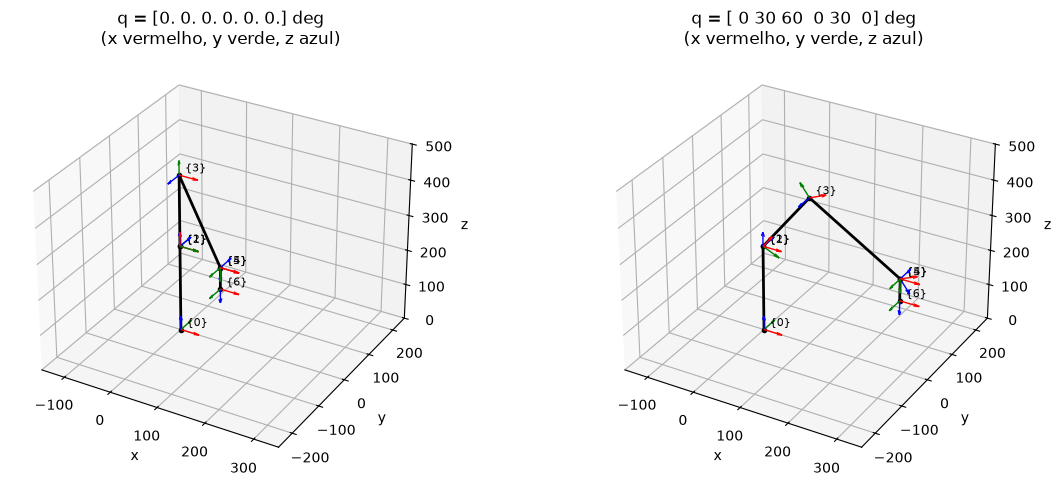

In [7]:
def draw_robot(ax, q, color="k", axes=False, alpha=1.0, label=None, garra=0.0):
    Ts = fk(q, all_frames=True)
    P = np.array([T[:3, 3] for T in Ts])
    ax.plot(*P.T, "-o", color=color, ms=3, lw=2, alpha=alpha, label=label)
    if garra:   # a pinça: do flange até à ponta, ao longo do z da ferramenta
        tip = (Ts[-1] @ tool_transform(garra))[:3, 3]
        ax.plot(*np.array([P[-1], tip]).T, color=color, lw=4, alpha=0.6)
    if axes:
        for i, T in enumerate(Ts):
            for k, c in zip(range(3), "rgb"):
                ax.quiver(*T[:3, 3], *(40 * T[:3, k]), color=c, lw=1)
            ax.text(*T[:3, 3] + 8, f"{{{i}}}", fontsize=8)
    return P

fig = plt.figure(figsize=(12, 5))
for j, q in enumerate([np.zeros(6), np.array([0, 30, 60, 0, 30, 0])]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    draw_robot(ax, q, axes=True)
    ax.set_title(f"q = {q} deg\n(x vermelho, y verde, z azul)")
    ax.set_xlim(-150, 350); ax.set_ylim(-250, 250); ax.set_zlim(0, 500)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.tight_layout(); plt.show()

### 2.5 Conversões de orientação

`rpy_from_R` / `R_from_rpy` seguem a convenção do SDK. `rotvec` é o logaritmo de
SO(3) (eixo × ângulo) e `orientation_error_deg` dá o ângulo entre duas
orientações — um só número, independente da convenção rpy. Teste de ida e volta
com orientações aleatórias:

In [8]:
rng = np.random.default_rng(0)
worst = 0
for _ in range(1000):
    rpy = rng.uniform([-180, -89, -180], [180, 89, 180])
    R = R_from_rpy(*rpy)
    worst = max(worst, orientation_error_deg(R_from_rpy(*rpy_from_R(R)), R))
print(f"pior erro ida-e-volta rpy -> R -> rpy em 1000 casos: {worst:.2e} deg")

pior erro ida-e-volta rpy -> R -> rpy em 1000 casos: 1.71e-06 deg


## 3. IK numérica (só para verificação offline)

A Tarefa 2 pede que se verifiquem limites e velocidades **das juntas** — é
preciso saber $q(t)$. A IK do robô só existe com o robô ligado, por isso há uma
IK própria em `ik_numeric()` (**não** é a da Tarefa 4).

**Mínimos quadrados amortecidos** (Levenberg-Marquardt):

$$
e = \begin{bmatrix} p^* - p(q) \\ w\cdot \log(R^* R(q)^T)^\vee \end{bmatrix},\qquad
\Delta q = J^T\,(J J^T + \lambda^2 I)^{-1}\, e
$$

- $J$ por diferenças finitas (0.0001° por junta); $w = 100$ equilibra rad com mm;
- $\lambda = 1$ evita passos enormes perto de singularidades;
- $q$ cortado aos limites das juntas; para quando o erro < 0.001 mm e < 1e-5 rad.

Na trajetória cada ponto começa na solução do anterior → juntas contínuas e
sempre o mesmo ramo de solução. Teste: FK de um q aleatório → IK → compara:

In [9]:
q_true = np.array([20, 40, 70, -30, 60, 15.0])
T_target = fk(q_true)
q_sol, conv = ik_numeric(T_target, q_true + 10)
print("q verdadeiro :", q_true)
print("q da IK      :", np.round(q_sol, 4), "| convergiu:", conv)
print(f"erro posição : {np.linalg.norm(fk(q_sol)[:3,3] - T_target[:3,3]):.2e} mm")

q verdadeiro : [ 20.  40.  70. -30.  60.  15.]
q da IK      : [ 20.  40.  70. -30.  60.  15.] | convergiu: True
erro posição : 2.91e-04 mm


## 4. Tarefa 2 — Trajetória de swing (`src/trajectory.py`)

### 4.1 A analogia com o Lab 1

No Lab 1 o swing era um **pêndulo duplo** (braço + pulso, com o pulso a soltar
tarde). Aqui a **garra faz de cabeça do taco**:

- **"braço"** → a garra percorre um arco de raio $R$ num plano vertical,
  centrado num ombro virtual por cima da bola; $\varphi = 0$ na bola:
  $$p(t) = \underbrace{b + R\hat z}_{\text{centro}} + R\big(\sin\varphi\,\hat d - \cos\varphi\,\hat z\big)$$
- **"pulso"** → a orientação roda $\varphi + \psi$ em torno da normal ao plano
  $\hat n = \hat d \times \hat z$: $\;R(t) = \mathrm{Rot}(-\hat n,\ \varphi+\psi)\,R_{\text{endereço}}$

### 4.2 As três fases

1. **Backswing** — quíntico $s(\tau)=10\tau^3-15\tau^4+6\tau^5$: $\varphi: 0\to\varphi_{top}$,
   $\psi: 0\to\psi_{top}$, com velocidade e aceleração nulas nos extremos.
2. **Downswing** — aceleração constante, como no Lab 1:
   $\varphi(u) = \varphi_{top}\,(1-(u/T)^2)$ ⇒ $\varphi(T)=0$ na bola com velocidade
   máxima $\omega_{imp} = -2\varphi_{top}/T$. O pulso fica armado até
   $f_{release}\,T$ e solta até $\psi=0$ no impacto.
3. **Follow-through** — desaceleração constante até parar em $\varphi_{end}$,
   durante $T_f = 2\varphi_{end}/\omega_{imp}$.

In [10]:
for k, v in DEFAULTS.items():
    print(f"{k:<14}: {v}")
p = DEFAULTS
w_imp = -2 * np.radians(p["phi_top"]) / p["t_down"]
T_f = 2 * np.radians(p["phi_end"]) / w_imp
print(f"\nomega no impacto = {w_imp:.3f} rad/s -> velocidade da garra na bola = {w_imp*p['raio']:.1f} mm/s")
print(f"T_follow = {T_f:.2f} s ; duração total = {p['t_back'] + p['t_down'] + T_f:.2f} s")

bola          : (190.0, 0.0, 80.0)
direcao       : (0.0, 1.0, 0.0)
raio          : 150.0
phi_top       : -90.0
phi_end       : 50.0
psi_top       : 30.0
f_release     : 0.6
t_back        : 2.0
t_down        : 2.2
rpy_enderecio : (180.0, 45.0, 0.0)
garra         : 83.6
dt            : 0.01

omega no impacto = 1.428 rad/s -> velocidade da garra na bola = 214.2 mm/s
T_follow = 1.22 s ; duração total = 5.42 s


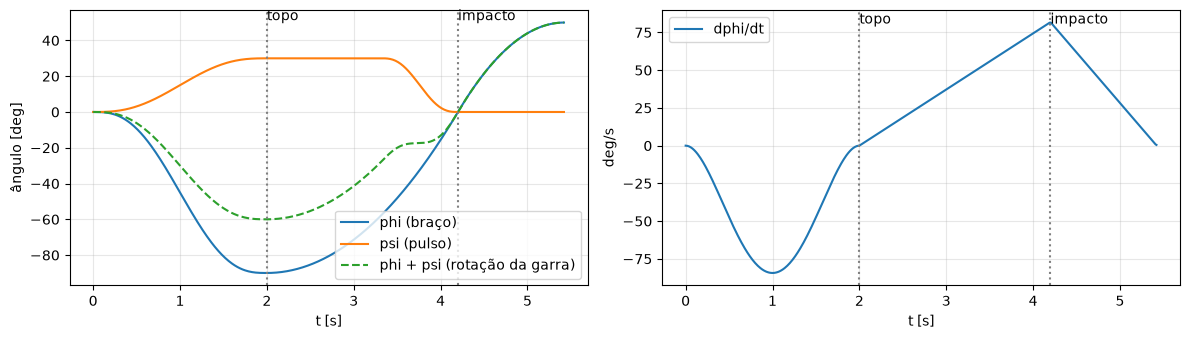

In [11]:
t, phi, psi = swing_angles(DEFAULTS)
tb, td = DEFAULTS["t_back"], DEFAULTS["t_down"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(t, np.degrees(phi), label="phi (braço)")
ax[0].plot(t, np.degrees(psi), label="psi (pulso)")
ax[0].plot(t, np.degrees(phi + psi), "--", label="phi + psi (rotação da garra)")
ax[1].plot(t, np.degrees(np.gradient(phi, t)), label="dphi/dt")
for a in ax:
    for x, s in [(tb, "topo"), (tb + td, "impacto")]:
        a.axvline(x, color="gray", ls=":"); a.text(x, a.get_ylim()[1] * 0.9, s)
    a.set_xlabel("t [s]"); a.legend(); a.grid(alpha=.3)
ax[0].set_ylabel("ângulo [deg]"); ax[1].set_ylabel("deg/s")
plt.tight_layout(); plt.show()

### 4.3 Gerar a trajetória e passar para o espaço das juntas

In [12]:
t0 = time.time()
traj = swing_trajectory()
qs, conv = joint_trajectory(traj)
print(f"{len(traj['t'])} pontos, {traj['t'][-1]:.2f} s, IK convergiu em todos: {conv}  ({time.time()-t0:.0f} s de cálculo)")

543 pontos, 5.42 s, IK convergiu em todos: True  (2 s de cálculo)


### 4.4 Verificação de viabilidade

| Verificação | Critério | Enunciado |
|---|---|---|
| vel. da garra | máx $\lVert\dot p\rVert \le 0.8 \times 500$ mm/s | (i) |
| vel. das juntas | máx $\lvert\dot q_i\rvert \le 0.8 \times 180$ °/s | (i) |
| alcance | distância ao ombro $\le 0.8 \times 440$ mm | (ii) |
| limites das juntas | $q_i \in$ `JOINT_LIMITS` | (iii) |
| acima da mesa | $z \ge 30$ mm | contacto perigoso |
| fora da base | distância ao eixo de J1 $\ge 80$ mm | contacto perigoso |

In [13]:
ok, extra = check_feasibility(traj, qs)
print("\n=> trajetória", "VIÁVEL" if ok and conv else "NÃO VIÁVEL")

  vel. TCP        : max    220.9 mm/s   (limite c/ margem 400.0)  OK
  vel. flange     : max    169.9 mm/s   (limite c/ margem 400.0)  OK
  vel. juntas     : max     94.7 deg/s  (limite c/ margem 144.0)  OK
  alcance         : max    270.0 mm     (limite c/ margem 352.0)  OK
  limites juntas  : menor folga 44.1 deg (J5, mínimo 5)  OK
  acima da mesa   : z min 80.0 mm (ponta 80.0, flange 139.1, juntas 139.1)  OK
  fora da base    : r min 190.0 mm  OK

=> trajetória VIÁVEL


### 4.5 Gráficos da trajetória (também gravados em `report/`)

  gráficos em C:\Users\Administrador\Desktop\ROB\Robotica26\Lab2\report


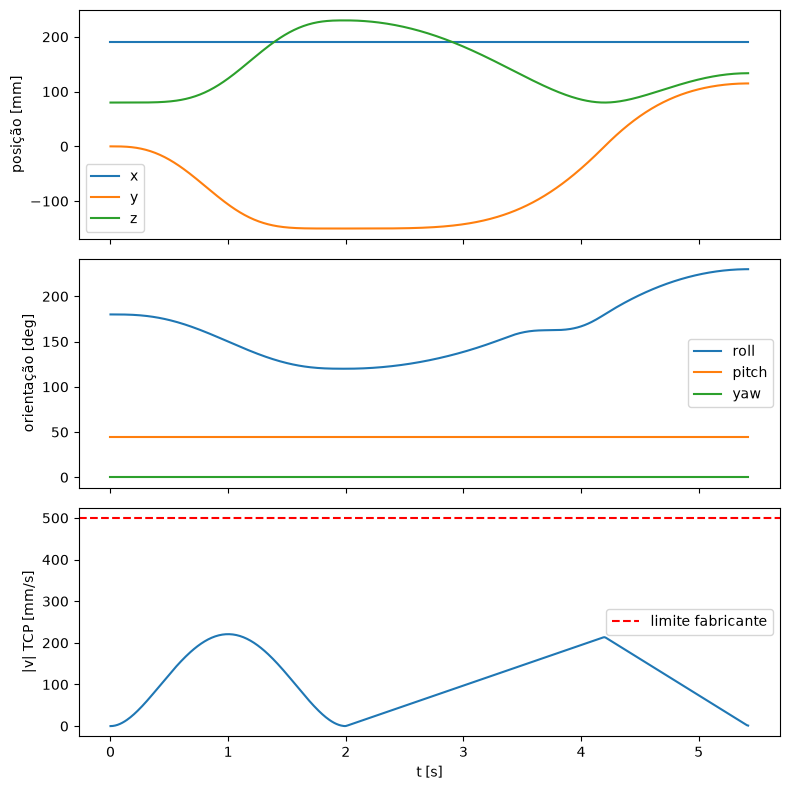

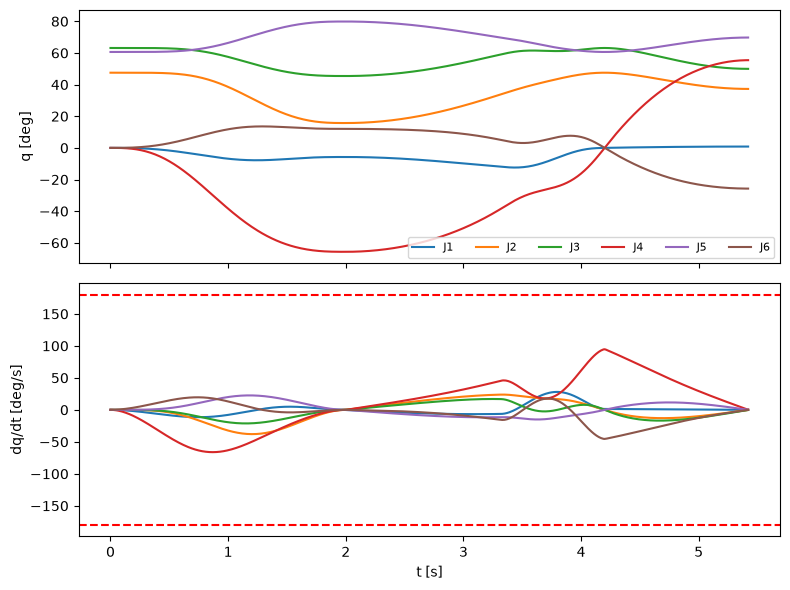

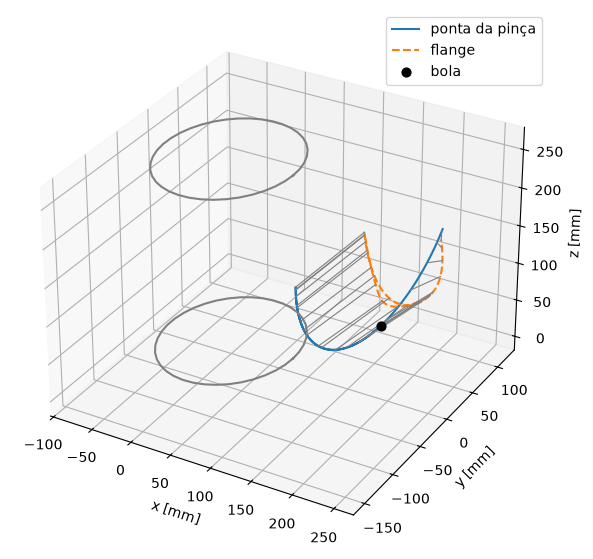

In [14]:
plot_traj(traj, qs, extra)
plt.show()

### 4.6 O robô nas fases do swing — prova de que não há contacto perigoso

Desenha-se o robô **com a pinça** (traço grosso, 83.6 mm; com os $q$ da IK) no endereço, no topo, no impacto e no fim,
junto com o caminho da garra, a bola, a mesa ($z=0$) e o cilindro da base.
Também se verifica a altura de **todas** as juntas (não só da garra) acima da mesa.

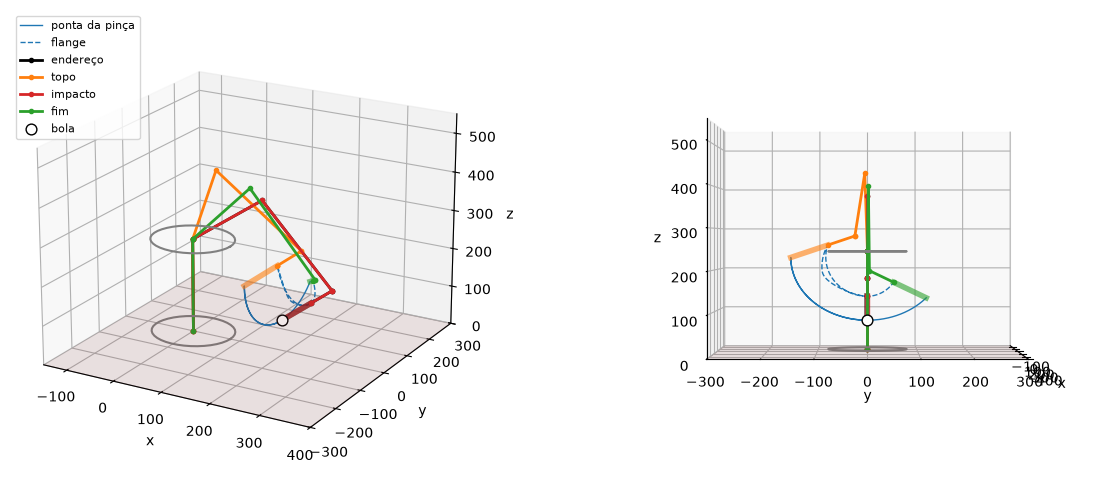

altura mínima de qualquer junta (J2..flange) ao longo do swing: 139.1 mm
altura mínima da ponta da pinça: 80.0 mm


In [15]:
t = traj["t"]
fases = {"endereço": 0,
         "topo": np.argmin(abs(t - tb)),
         "impacto": np.argmin(abs(t - tb - td)),
         "fim": len(t) - 1}
fig = plt.figure(figsize=(13, 5))
for j, (elev, azim) in enumerate([(20, -60), (0, 0)]):
    ax = fig.add_subplot(1, 2, j + 1, projection="3d")
    ax.plot(*traj["pos"].T, color="tab:blue", lw=1, label="ponta da pinça")
    ax.plot(*traj["pos_flange"].T, color="tab:blue", lw=1, ls="--", label="flange")
    for (nome, k), c in zip(fases.items(), ["k", "tab:orange", "tab:red", "tab:green"]):
        draw_robot(ax, qs[k], color=c, label=nome, garra=DEFAULTS["garra"])
    ax.scatter(*DEFAULTS["bola"], s=60, color="w", edgecolor="k", label="bola")
    th = np.linspace(0, 2*np.pi, 40)
    for z in (0, 243.3):
        ax.plot(C.BASE_RADIUS*np.cos(th), C.BASE_RADIUS*np.sin(th), z, color="gray")
    xx, yy = np.meshgrid([-150, 400], [-300, 300])
    ax.plot_surface(xx, yy, 0*xx, alpha=.1, color="brown")
    ax.view_init(elev, azim); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_xlim(-150, 400); ax.set_ylim(-300, 300); ax.set_zlim(0, 550)
    if j == 0: ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

z_min_juntas = min(min(T[2, 3] for T in fk(q, all_frames=True)[2:]) for q in qs)
print(f"altura mínima de qualquer junta (J2..flange) ao longo do swing: {z_min_juntas:.1f} mm")
print(f"altura mínima da ponta da pinça: {traj['pos'][:, 2].min():.1f} mm")

## 5. A singularidade do pulso

**Primeira tentativa:** garra a pique para a bola, `rpy_enderecio = (180, 0, 0)`,
`t_down = 1.5 s`. Com a garra vertical, o eixo de J6 alinha com o de J4 —
acontece quando **J5 = 0**. É a singularidade dos pulsos esféricos: J4 e J6
passam a fazer o mesmo, o jacobiano perde característica, e pequenas mudanças de
orientação exigem rotações enormes e opostas de J4 e J6.

Comparação de várias orientações de endereço (com `dt = 0.02` para ser mais
rápido — os valores diferem um pouco dos do guia, que usou `dt = 0.01`):

In [16]:
def resumo(params):
    tr = swing_trajectory(params)
    q, c = joint_trajectory(tr)
    qd = np.gradient(q, tr["t"], axis=0)
    return tr, q, c, np.abs(qd).max(0)

# a história da singularidade foi feita antes da pinça: repõe esses parâmetros
ORIGINAL = dict(garra=0.0, bola=(250.0, 0.0, 80.0), phi_top=-100.0, phi_end=80.0)
casos = {}
print("rpy endereço      convergiu   máx |dq/dt| J1..J6 [deg/s]          J5 min..max")
for rpy in [(180, 0, 0), (180, 30, 0), (180, -30, 0), (180, 45, 0)]:
    tr, q, c, vmax = resumo(dict(ORIGINAL, rpy_enderecio=rpy, t_down=1.5, dt=0.02))
    casos[rpy] = (tr, q)
    print(f"{str(rpy):<16}  {str(c):<9}  {np.round(vmax, 0)}   {q[:,4].min():6.1f}..{q[:,4].max():6.1f}")

rpy endereço      convergiu   máx |dq/dt| J1..J6 [deg/s]          J5 min..max


(180, 0, 0)       False      [ 52.  37.  13. 803. 143. 848.]    -74.9..  62.9


(180, 30, 0)      True       [ 47.  39.  14. 258.  60. 172.]     36.3..  77.6


(180, -30, 0)     True       [ 58.  41.   7. 180.  51. 192.]    -75.0.. -30.8


(180, 45, 0)      True       [ 45.  42.  21. 201.  39.  94.]     52.8..  79.8


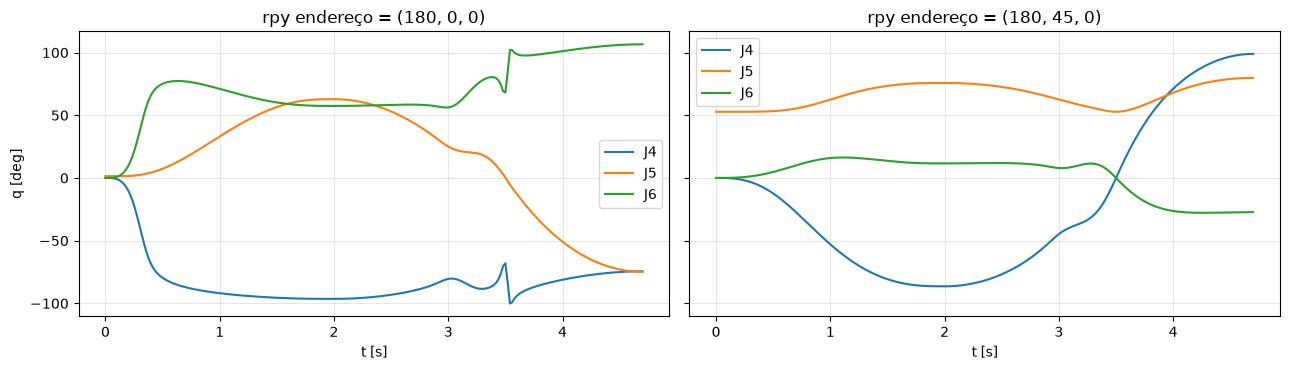

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, rpy in zip(ax, [(180, 0, 0), (180, 45, 0)]):
    tr, q = casos[rpy]
    for j in (3, 4, 5):
        a.plot(tr["t"], q[:, j], label=f"J{j+1}")
    a.set_title(f"rpy endereço = {rpy}"); a.set_xlabel("t [s]"); a.grid(alpha=.3); a.legend()
ax[0].set_ylabel("q [deg]")
plt.tight_layout(); plt.show()

À esquerda, J5 passa por ~0 e J4/J6 dão saltos; à direita, J5 fica longe de 0 e
tudo é suave. Com 45° o pulso (J4/J6) continuava acima dos 144 °/s; como as
velocidades escalam com $1/T$, **`t_down` passou de 1.5 para 2.2 s**
($\approx 180 \times 1.5/2.2 \approx 123$ °/s).

**Conclusão para o relatório:** o limite do swing neste robô não é a velocidade
linear da garra (≈ 240 mm/s ≪ 500 mm/s) mas a da **junta 6**; e a orientação da
garra tem de ser escolhida para evitar a singularidade do pulso.

### 5.1 A pinça: alcance e limite de J5

O robô tem a **UFACTORY Gripper for Lite 6**: TCP (entre as pontas dos dedos) a
**83.6 mm** do flange ao longo do z da ferramenta (URDF oficial `xarm_ros2`,
`uflite_gripper.urdf.xacro`), 290 g. A cabeça do taco passa a ser a **ponta da
pinça**; o flange fica 83.6 mm atrás:
$p_{flange} = p_{ponta} - 83.6\,\hat z_{ferramenta}$.

Com a bola em (250, 0, 80) e φ de −100° a 80°, isto deu dois problemas:
1. o flange no topo saía do alcance → **bola aproximada para x = 190 mm**;
2. a **J5 chegava ao limite físico (124°)** no topo e no fim → φ passou a
   −90° … 70°;
3. no laboratório, com φ_end = 70° o robô parava sempre com **C31** (deteção de
   colisão) no fim do follow-through → **φ_end final = 50°** (J5 no fim: 92° em vez de 112°).

caso                               conv   alcance máx   J5 min..max


sem pinça, bola 250, -100/80       True      298.6 mm    52.8.. 79.8


pinça, bola 190, -100/80           True      270.0 mm    60.6.. 84.2


pinça, bola 190, -90/70            True      270.0 mm    60.6.. 79.9


pinça, bola 190, -90/50 (final)    True      270.0 mm    60.6.. 79.9


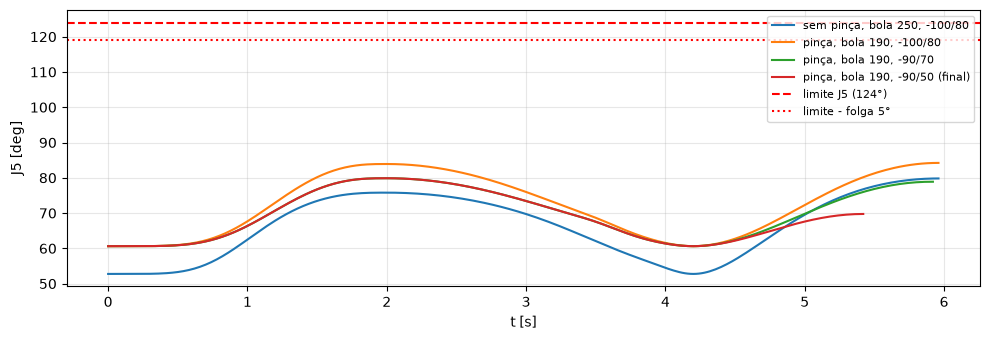

In [18]:
casos_p = {"sem pinça, bola 250, -100/80": dict(ORIGINAL),
           "pinça, bola 190, -100/80":     dict(garra=C.GRIPPER_TCP_Z, bola=(190.0, 0.0, 80.0), phi_top=-100.0, phi_end=80.0),
           "pinça, bola 190, -90/70":        dict(phi_end=70.0),
           "pinça, bola 190, -90/50 (final)": dict()}
fig, ax = plt.subplots(figsize=(10, 3.5))
print("caso                               conv   alcance máx   J5 min..max")
for nome, p in casos_p.items():
    tr, q, c, vmax = resumo(dict(p, dt=0.02))
    alc = np.linalg.norm(tr["pos_flange"] - fk(np.zeros(6), all_frames=True)[2][:3, 3], axis=1).max()
    print(f"{nome:<34} {str(c):<6} {alc:8.1f} mm   {q[:,4].min():5.1f}..{q[:,4].max():5.1f}")
    ax.plot(tr["t"], q[:, 4], label=nome)
ax.axhline(124, color="r", ls="--", label="limite J5 (124°)")
ax.axhline(124 - C.JOINT_LIMIT_MARGIN, color="r", ls=":", label="limite - folga 5°")
ax.set_xlabel("t [s]"); ax.set_ylabel("J5 [deg]"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

No robô, o SDK move o TCP configurado no controlador (`arm.tcp_offset`). O
código **lê-o sem o alterar** e converte cada pose:
$T_{enviar} = T_{ponta}\,T_{garra}^{-1}\,T_{ctrl}$. Teste com três offsets
possíveis — a ponta da pinça tem de cair sempre na bola:

In [19]:
k_imp = np.argmin(abs(traj["t"] - tb - td))
for nome, T_ctrl in [("controlador sem offset (flange)", np.eye(4)),
                     ("controlador com a pinça (83.6)", tool_transform(83.6)),
                     ("offset arbitrário", T_from_pose([5, -3, 70, 0, 0, 10]))]:
    cmds = command_poses(traj, T_ctrl)
    erro = max(np.linalg.norm(fk_pose(q, T_ctrl)[:3] - np.array(cmd[:3])) for q, cmd in zip(qs, cmds))
    ponta = (fk(qs[k_imp]) @ tool_transform(DEFAULTS["garra"]))[:3, 3]
    print(f"{nome:<32} 1.ª pose enviada {np.round(cmds[0], 1)}  | erro FK {erro:.4f} mm | ponta no impacto {np.round(ponta, 2)}")

controlador sem offset (flange)  1.ª pose enviada [ 249.1    0.   139.1 -180.    45.     0. ]  | erro FK 0.0006 mm | ponta no impacto [190.  -0.  80.]
controlador com a pinça (83.6)   1.ª pose enviada [ 190.    0.   80. -180.   45.    0.]  | erro FK 0.0011 mm | ponta no impacto [190.  -0.  80.]
offset arbitrário                1.ª pose enviada [203.2   3.   86.1 170.1  44.1 -14. ]  | erro FK 0.0010 mm | ponta no impacto [190.  -0.  80.]


## 6. Explorar parâmetros

Função `testar(**params)` — muda o que quiseres dos `DEFAULTS` e vê se continua
viável. Exemplo: varrimento de `t_down` (com `dt = 0.02` para ser rápido).

In [20]:
def testar(verbose=False, **params):
    tr = swing_trajectory(params)
    q, c = joint_trajectory(tr)
    ok, ex = check_feasibility(tr, q, verbose=verbose)
    return ok and c, ex["v_tcp"].max(), np.abs(ex["qd"]).max(0)

print("t_down [s]   viável   v_TCP máx [mm/s]   máx |dq/dt| J1..J6 [deg/s]")
for td_ in [1.5, 1.8, 2.0, 2.2, 2.6]:
    ok_, v, qd = testar(t_down=td_, dt=0.02)
    print(f"{td_:8.1f}     {str(ok_):<6}   {v:10.1f}         {np.round(qd, 0)}")

t_down [s]   viável   v_TCP máx [mm/s]   máx |dq/dt| J1..J6 [deg/s]


     1.5     True          311.1         [ 41.  38.  25. 138.  23.  66.]


     1.8     True          259.7         [ 34.  38.  21. 115.  23.  55.]


     2.0     True          233.9         [ 31.  38.  21. 104.  23.  50.]


     2.2     True          220.8         [28. 38. 21. 94. 23. 45.]


     2.6     True          220.8         [24. 38. 21. 80. 23. 38.]


| Quero… | Mexer em | Cuidado |
|---|---|---|
| swing mais rápido | `t_down` ↓ | J6 é o primeiro a passar o limite |
| backswing mais lento | `t_back` ↑ | hoje o pico do backswing (~221 mm/s) é maior que o do impacto (~214 mm/s) |
| arco maior | `raio` ↑ | alcance e topo |
| backswing mais alto | `phi_top` mais negativo | ω de impacto e alcance |
| pulso mais ativo | `psi_top`, `f_release` ↑ | carga em J6 |
| bola noutro sítio | `bola` | alcance, mesa, base |
| outra orientação | `rpy_enderecio` | manter J5 longe de 0 |
| sem pinça / outra ferramenta | `garra` | mm do flange à ponta; 0 = sem pinça |

## 7. Tarefa 3 — Executar no robô (`src/run_robot.py`)

Fluxo: gera a trajetória **esticada** por `LENTO` → verifica viabilidade (se
falhar, não envia) → liga → vai à pose inicial a 50 mm/s → executa.

| Método | Como | Prós / contras |
|---|---|---|
| `pontos` | modo 0, `set_position(..., radius=5, wait=False)` em 1 de cada 10 pontos, com a velocidade média de cada troço | robusto; o controlador suaviza, o perfil fica aproximado |
| `servo` | modo 1, `set_servo_cartesian()` a cada `dt`; lê a pose real e grava `data/run_servo.csv` | segue o perfil à risca; mais exigente em tempo real |

**Segurança:** emergência à mão; começar com `LENTO = 3`; só mudar
`RUN_ON_ROBOT` para `True` com o robô livre.

Pela linha de comandos: `python src/run_robot.py` (ensaio) e
`python src/run_robot.py --go --lento 3`.

In [21]:
RUN_ON_ROBOT = False      # <- True só no laboratório, com o robô livre
METODO = "pontos"         # "pontos" ou "servo"
LENTO = 3.0

traj_r = swing_trajectory({k: DEFAULTS[k] * LENTO for k in ("t_back", "t_down")})
qs_r, conv_r = joint_trajectory(traj_r)
ok_r, _ = check_feasibility(traj_r, qs_r)
print(f"\nponta da pinça no início {np.round(traj_r['pos'][0], 1)}  duração {traj_r['t'][-1]:.1f} s  viável: {ok_r and conv_r}")

if RUN_ON_ROBOT and ok_r and conv_r:
    from robot import connect, check, controller_tcp
    from run_robot import run_pontos, run_servo, APPROACH_SPEED
    arm = connect()
    try:
        print("tcp_offset do controlador:", np.round(arm.tcp_offset[:6], 2))
        cmds = command_poses(traj_r, controller_tcp(arm))   # converte para o TCP do controlador
        check(arm.set_position(*cmds[0], speed=APPROACH_SPEED, wait=True), "set_position (início)")
        run_pontos(arm, traj_r, cmds, every=10) if METODO == "pontos" else run_servo(arm, traj_r, cmds)
    finally:
        arm.disconnect()
else:
    print("ENSAIO — nada foi enviado ao robô.")

  vel. TCP        : max     73.6 mm/s   (limite c/ margem 400.0)  OK
  vel. flange     : max     56.6 mm/s   (limite c/ margem 400.0)  OK
  vel. juntas     : max     31.6 deg/s  (limite c/ margem 144.0)  OK
  alcance         : max    270.0 mm     (limite c/ margem 352.0)  OK
  limites juntas  : menor folga 44.1 deg (J5, mínimo 5)  OK
  acima da mesa   : z min 80.0 mm (ponta 80.0, flange 139.1, juntas 139.1)  OK
  fora da base    : r min 190.0 mm  OK

ponta da pinça no início [190.   0.  80.]  duração 16.3 s  viável: True
ENSAIO — nada foi enviado ao robô.


Depois de um ensaio em `servo`, comparar referência e pose medida:

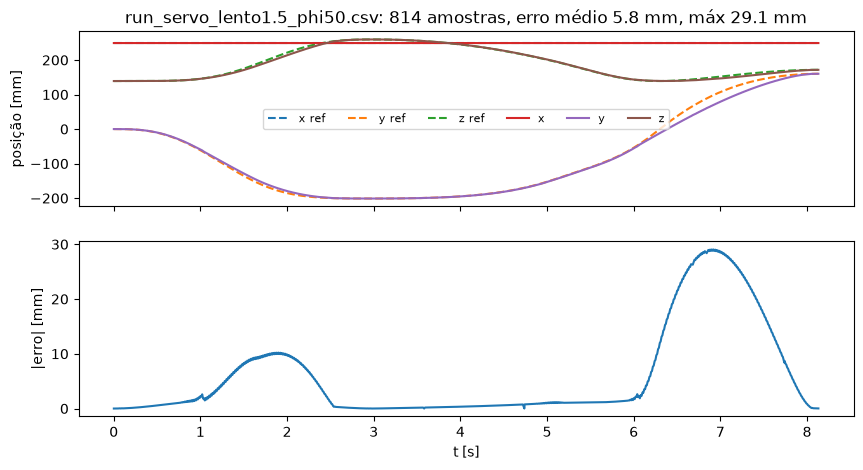

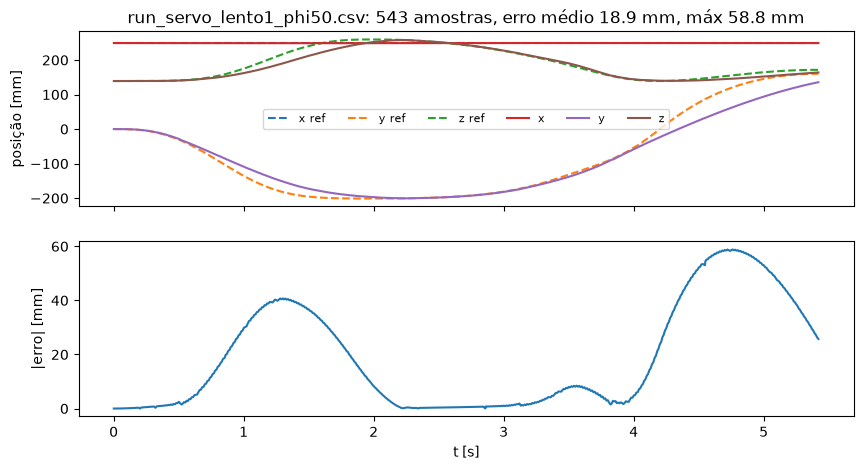

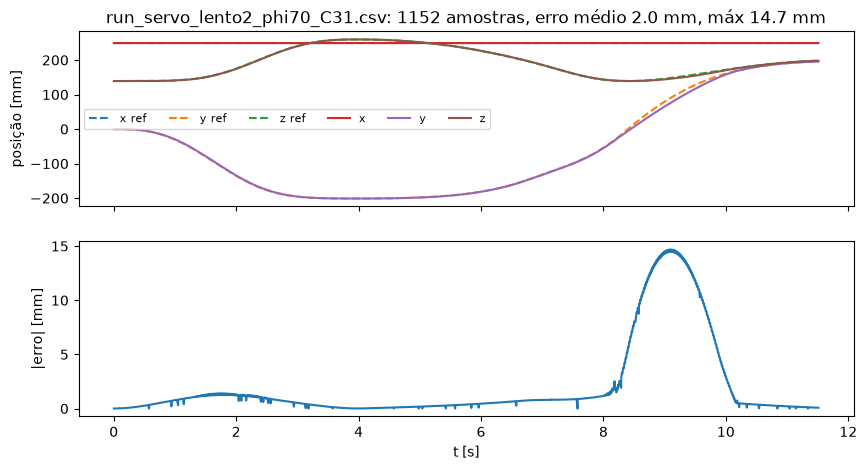

In [22]:
import glob
for csv in sorted(glob.glob(os.path.join("data", "run_servo_*.csv"))):
    d = np.loadtxt(csv, delimiter=",")
    err = np.linalg.norm(d[:, 7:10] - d[:, 1:4], axis=1)
    fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
    ax[0].plot(d[:, 0], d[:, 1:4], "--"); ax[0].plot(d[:, 0], d[:, 7:10])
    ax[0].set_ylabel("posição [mm]"); ax[0].legend(["x ref", "y ref", "z ref", "x", "y", "z"], ncol=6, fontsize=8)
    ax[1].plot(d[:, 0], err); ax[1].set_ylabel("|erro| [mm]"); ax[1].set_xlabel("t [s]")
    ax[0].set_title(f"{os.path.basename(csv)}: {len(d)} amostras, erro médio {err.mean():.1f} mm, máx {err.max():.1f} mm")
    plt.show()

## 8. Tarefa 4 — Precisão da IK do robô (`src/ik_compare.py`)

Para $N$ pontos espalhados por toda a trajetória:

1. $q_{sdk}$ = `arm.get_inverse_kinematics(pose_ref)` — **IK do robô**;
2. $\text{pose}_{fk}$ = `fk_pose(q_sdk)` — **a nossa FK** (Tarefa 1);
3. erro de posição $\lVert p_{fk}-p_{ref}\rVert$ e de orientação (ângulo entre as duas).

As poses referem-se ao TCP do controlador (`tcp_offset`, p.ex. a ponta da
pinça); a nossa FK compõe-se com o mesmo offset, $fk(q)\,T_{ctrl}$.

Extra: `arm.get_forward_kinematics(q_sdk)` — se coincidir com a nossa FK, **a
tabela DH fica validada contra o controlador**.

| Se… | então… |
|---|---|
| nossa FK = FK do robô, erro pequeno | IK do robô precisa e FK certa |
| nossa FK = FK do robô, erro grande nalguns pontos | imprecisão da IK ali (singularidade? limites?) |
| nossa FK ≠ FK do robô | erro na tabela DH ou offset da ferramenta — corrigir antes de concluir |

Não ativa os motores — é seguro. Linha de comandos:
`python src/ik_compare.py --n 60` (no lab) e `--from-csv` (em casa).

a usar dados reais de C:\Users\Administrador\Desktop\ROB\Robotica26\Lab2\src\..\data\ik_compare.csv
  IK do robô + nossa FK vs referência: posição  média 1.4792  máx 2.0967 mm
                                       orient.  média 0.0619  máx 0.0875 deg
  nossa FK vs FK do controlador      : posição  máx 2.0967 mm
  gráfico em C:\Users\Administrador\Desktop\ROB\Robotica26\Lab2\report\ik_erros.png


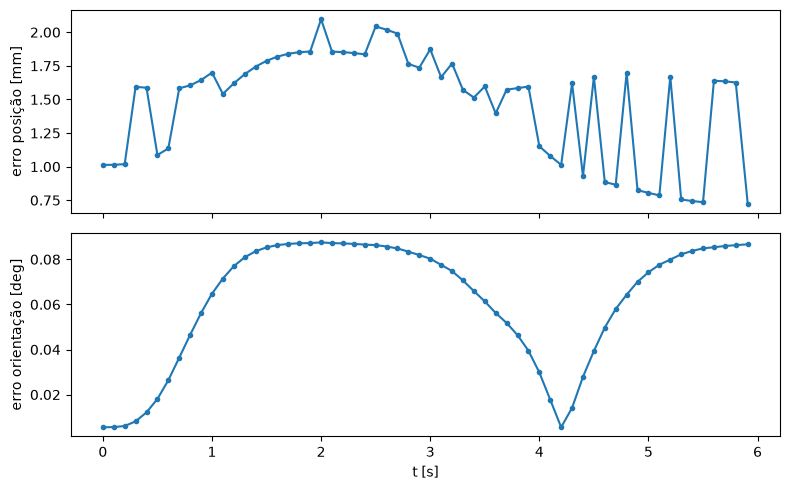

In [23]:
RUN_IK_ON_ROBOT = False   # <- True no laboratório (não mexe o robô)
N = 60
import ik_compare as ic

if RUN_IK_ON_ROBOT:
    rows = ic.collect(N, None)
elif os.path.exists(ic.CSV):
    rows = np.loadtxt(ic.CSV, delimiter=",")
    print("a usar dados reais de", ic.CSV)
else:
    rows = None
    print("sem dados do robô ainda — ver a simulação abaixo")
if rows is not None:
    ic.analyse(rows); plt.show()

### 8.1 Simulação (só para testar a análise)

Sem robô, substitui-se a IK do controlador pela nossa IK numérica. Os erros dão
praticamente zero, o que só prova que a análise funciona — **não é o resultado
da Tarefa 4**.

  IK do robô + nossa FK vs referência: posição  média 0.0004  máx 0.0006 mm
                                       orient.  média 0.0004  máx 0.0006 deg
  nossa FK vs FK do controlador      : posição  máx 0.0000 mm
  gráfico em C:\Users\ADMINI~1\AppData\Local\Temp\ik_erros.png


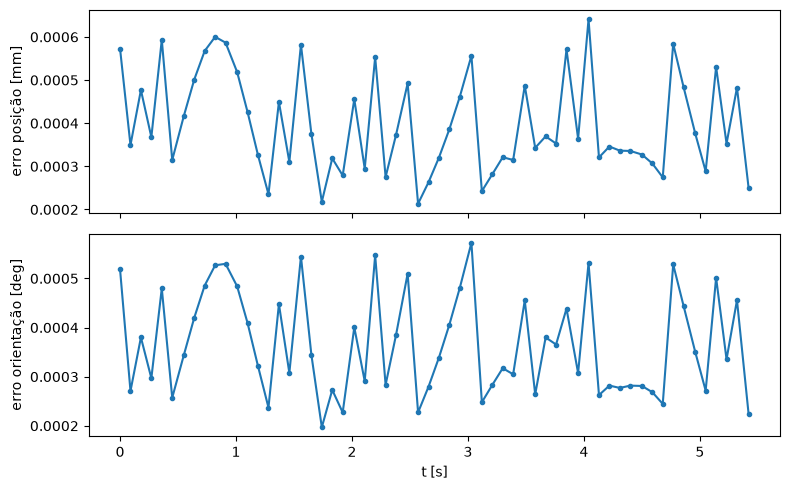

In [24]:
idx = np.linspace(0, len(traj["t"]) - 1, N).astype(int)
T_ctrl = tool_transform(C.GRIPPER_TCP_Z)      # "controlador" com o TCP na ponta da pinça
cmds = command_poses(traj, T_ctrl)
sim = []
for k in idx:
    q = qs[k]                                  # "IK" = a nossa IK numérica
    sim.append([traj["t"][k], *cmds[k], *q, *fk_pose(q, T_ctrl), *fk_pose(q, T_ctrl), 0, 0, C.GRIPPER_TCP_Z, 0, 0, 0])
sim = np.array(sim)
REPORT_BAK = ic.REPORT
import tempfile
ic.REPORT = tempfile.gettempdir()              # não sobrescreve report/ik_erros.png
ic.analyse(sim); plt.show()
ic.REPORT = REPORT_BAK

### 8.2 O que discutir no relatório

- ordem de grandeza dos erros face à repetibilidade do robô (datasheet);
- onde estão os maiores erros e se coincidem com J5 pequeno ou juntas perto dos limites;
- se a IK do robô escolhe sempre a mesma configuração (cotovelo/pulso);
- pontos em que a IK do robô falhou (código ≠ 0).

## 9. Checklist do laboratório e limitações

**Antes de ir**
- [x] Tabela DH confirmada com o PDF oficial (secção 2.2).
- [ ] Confirmar limites e velocidades na datasheet; voltar a correr este notebook.
- [ ] Portátil com a `.venv` pronta; exemplos do curso em `scripts_curso/`.

**No laboratório**
1. [ ] IP na caixa de controlo; portátil com IP fixo na mesma sub-rede; `LITE6_IP`.
2. [ ] Correr um exemplo do curso para testar a ligação.
3. [ ] Confirmar que a pinça é a Gripper Lite (83.6 mm no código); o `tcp_offset` é lido automaticamente.
4. [ ] Mesa ao nível da base; espaço livre à volta da bola (190, 0, 80).
5. [ ] **Tarefa 4 primeiro** (não mexe): `RUN_IK_ON_ROBOT = True`.
6. [ ] Tarefa 3: ensaio → `LENTO = 3` → baixar aos poucos → `servo` para gravar CSV.
7. [ ] Filmar o swing; guardar `data/` e commitar.

**Limitações conhecidas**
- Limites e velocidades do fabricante por confirmar (a tabela DH está confirmada).
- A bola é um ponto (sem tamanho de bola/garra).
- Colisões: garra vs mesa/base; as juntas só são verificadas acima da mesa (secção 4.6), os elos não.
- Aceleração descontínua na passagem downswing → follow-through.
- Acelerações das juntas não verificadas.
- Modo servo: `get_position()` em cada passo pode atrasar o ciclo de 10 ms.
- IK do robô chamada sem configuração de referência.